In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
from itertools import cycle
import os
from functools import partial

import mlflow
import matplotlib.pyplot as plt
from networkx import number_weakly_connected_components
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.ModelRunner import run_training_job, ModelRunner
from halcyon.Simulators import NoiseLevel, SimulationResult

from halcyon.Models import PhoenixAddAndProdLayers, PyTorchODE, HybridModel
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero
from halcyon.Models.Losses import MSELossPlusMachineLearningL2


seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 


True

Check if MLFlow connects correctly

In [2]:
print(os.getenv("MLFLOW_TRACKING_URI"))

https://mlflow.cropresilience.org


In [3]:
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

# Input data

## Downloading data from MLFlow

In [4]:
sim_run_id_to_use = "6b42a380ce444748a04738cc3395c52d"  
run = mlflow.get_run(sim_run_id_to_use)

params = run.data.params
print(params)

{'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '2', 'noise_level': 'ALLNOISE', 'seed': '174'}


In [5]:
ml_flow_download_path = mlflow.artifacts.download_artifacts(run_id=sim_run_id_to_use, artifact_path="dataset")
sim_output = SimulationResult.load_from_pkl(Path(ml_flow_download_path) / "simulation_result.pkl")

## Convert sim output into datasets for use with the trainer object

In [6]:
# From sim output to datasets
single_ko_dataset, double_ko_dataset, time_scaling_factor = sim_output.create_datasets()
dataset_dict = {
    "single_ko": single_ko_dataset,
    "double_ko": double_ko_dataset,}

# Trainers (with different models) creation

In [7]:
train_jobs : list[ModelRunner] = []
device = cycle(['cuda:0', 'cuda:1'])
batch_size = 32
nr_epochs = 20

## Mech model

Assigning only one cluster of genes to this MM

1


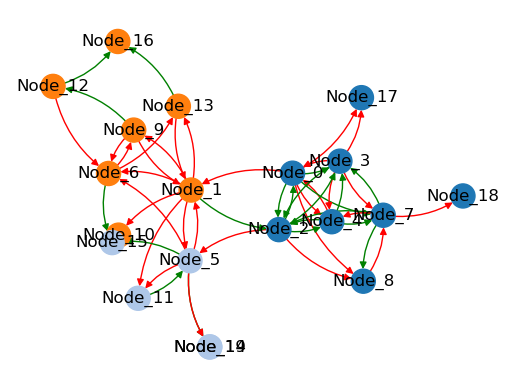

In [8]:
sim_output.network.do_clustering()

print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

In [9]:
node_that_should_be_in_model = 'Node_18'
for i, module in enumerate(sim_output.network._clustering):
    if node_that_should_be_in_model in module:
        print('Module:', i)
        print('Size:', len(module))
        genes_to_select = list(sim_output.network._clustering[i])
        break

Module: 0
Size: 8


Generate MM from this subset

In [10]:
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml',
                           condition_names=[], from_gnw=True, device=next(device))
# Select only genes from specific module and set timescaler
mm.select_genes(genes_to_select, 
                goldstandard_signed_file_for_expression_substitution = sim_output.data_path / f'{sim_output.network_name}_goldstandard_signed.tsv')
mm.set_timescaler(time_scaling_factor)

print(mm.modelled_gene_labels)

# Creating MM trainer even though it cannot be trained
mm_trainer = ModelRunner(
    mm,
    nr_epochs=0,
    batch_size=batch_size,
)

train_jobs.append(mm_trainer)

['Node_7', 'Node_2', 'Node_3', 'Node_4', 'Node_8', 'Node_0', 'Node_17', 'Node_18']


## ML and Hybrid model

In [11]:
for hidden_size in [10]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=single_ko_dataset.genes,
                    hidden_size=hidden_size,
                    condition_names=single_ko_dataset.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device=next(device)
            )

        # Create hybrid model with MM and with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device=next(device))
        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            model_runner = ModelRunner(
                model = model,
                batch_size=batch_size,
                nr_epochs=nr_epochs,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(model_runner)

## Baseline model (always derivative of 0)

In [12]:
baseline_model = AlwaysDerivativeZero(
    modelled_gene_labels=single_ko_dataset.genes,
    condition_names=single_ko_dataset.all_environments
    )

baseline_trainer = ModelRunner(
    baseline_model,
    batch_size=batch_size,
    nr_epochs=0,
)
train_jobs.append(baseline_trainer)

In [13]:
for job in train_jobs:
    print(job)
    print()

Modelrunner (Model=PyTorchODE with hyperparams: [],
 optimizer=Adam,
 optimizer_kwargs={},
 nr_epochs=0,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=10', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:0', 'hidden_size=10', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

Modelrunner (Model=AlwaysDerivativeZero with hyperparams: [],
 optimizer=Adam,
 optimizer_kwargs={},
 nr_epochs=0,
 batch_size=32
)



In [15]:
train_jobs[1]

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=10', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=20,
 batch_size=32
)

In [16]:
train_jobs[1].train_and_predict_for_mlflow(dataset_dict=dataset_dict, 
                                           train_data_key_in_dict='single_ko',
                                           simulation_parent_id=sim_run_id_to_use,
                                           save_every_n_epochs=5)

2026-03-10 11:56:26,277 [MainProcess] Epoch 0, loss 0.16208027303218842
2026-03-10 11:56:27,352 [MainProcess] Epoch 1, loss 0.09016458690166473
2026-03-10 11:56:28,448 [MainProcess] Epoch 2, loss 0.05392662063241005
2026-03-10 11:56:29,722 [MainProcess] Epoch 3, loss 0.05614979937672615
2026-03-10 11:56:31,104 [MainProcess] Epoch 4, loss 0.0536111555993557
2026-03-10 11:56:32,813 [MainProcess] Epoch 5, loss 0.05043218657374382
2026-03-10 11:56:34,185 [MainProcess] Epoch 6, loss 0.04746188968420029
2026-03-10 11:56:35,566 [MainProcess] Epoch 7, loss 0.044886551797389984
2026-03-10 11:56:36,953 [MainProcess] Epoch 8, loss 0.0415126234292984
2026-03-10 11:56:38,525 [MainProcess] Epoch 9, loss 0.0378631167113781
2026-03-10 11:56:40,348 [MainProcess] Epoch 10, loss 0.03530474752187729
2026-03-10 11:56:42,251 [MainProcess] Epoch 11, loss 0.03346952050924301
2026-03-10 11:56:44,193 [MainProcess] Epoch 12, loss 0.032586317509412766
2026-03-10 11:56:46,218 [MainProcess] Epoch 13, loss 0.0313581

🏃 View run PhoenixAddAndProdLayers at: https://mlflow.cropresilience.org/#/experiments/3/runs/5e03574849b04d7eb8193c2e257de82f
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


# Do training

In [ ]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(
        partial(
            run_training_job, 
            dataset_dict=dataset_dict, 
            train_data_key_in_dict="single_ko", 
            simulation_parent_id=sim_run_id_to_use, 
            do_mlflow_model_logging=False,
        ),
        train_jobs
    )

# All files have now been logged to MLFlow

To see how to process this data further look into the MLFlow loading and plotting notebook(s)